# **Labsheet - 4**

**1. Build a tool that computes and visualizes the 2D Fourier spectrum(magnitude and phase) of an image.**

Saving pic(butterfly).jpg to pic(butterfly).jpg


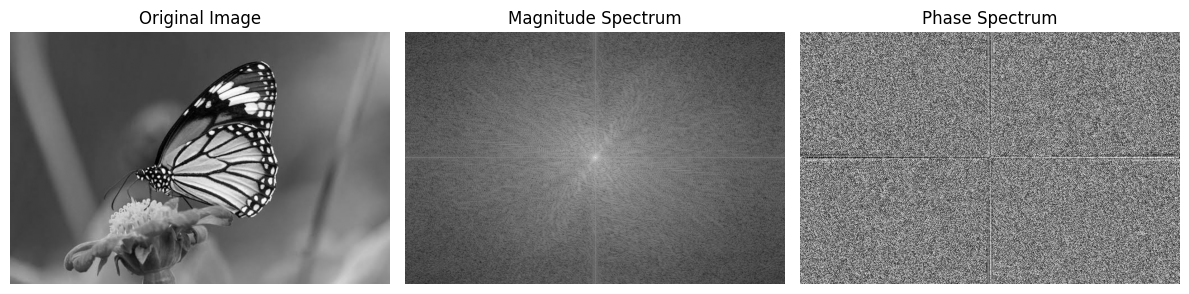

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# Upload image
uploaded = files.upload()

# Get uploaded filename
filename = next(iter(uploaded))

# Read image
img = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)

# Check whether image was loaded
if img is None:
    print("Error: Image could not be loaded.")
else:
    # Compute 2D Fourier Transform
    f = np.fft.fft2(img)

    # Shift zero frequency to center
    fshift = np.fft.fftshift(f)

    # Magnitude spectrum
    magnitude = 20 * np.log(np.abs(fshift) + 1)

    # Phase spectrum
    phase = np.angle(fshift)

    # Display
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(img, cmap='gray')
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(magnitude, cmap='gray')
    plt.title("Magnitude Spectrum")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(phase, cmap='gray')
    plt.title("Phase Spectrum")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

**Mishti Verma, CU24250174**

**2. Develop a frequency-domain low-pass filter(ideal,Butterworth and Gaussian) and compare the resulting blur effects.**

Saving pic(dog).jpg to pic(dog).jpg


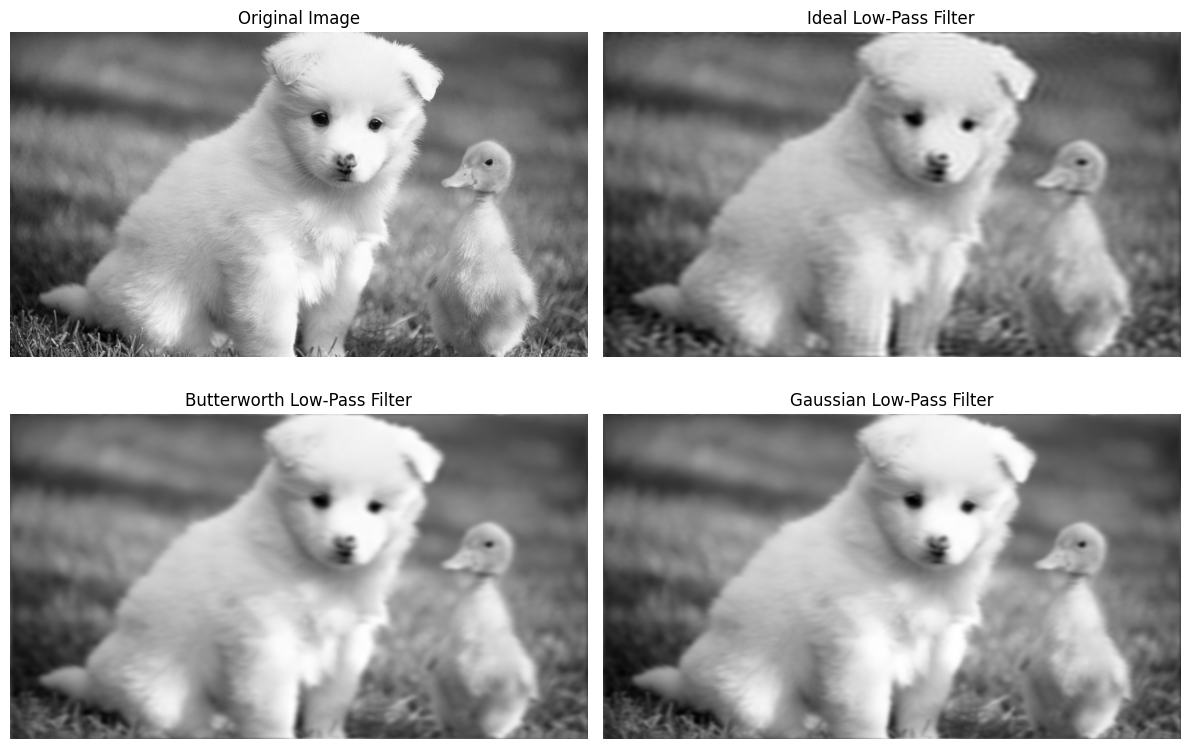

In [ ]:
# Upload image
uploaded = files.upload()
filename = next(iter(uploaded))

# Read image in grayscale
img = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Error: Image could not be loaded.")
else:
    # Fourier Transform
    f = np.fft.fft2(img)
    fshift = np.fft.fftshift(f)

    rows, cols = img.shape
    crow, ccol = rows // 2, cols // 2

    # Create distance matrix
    y, x = np.ogrid[:rows, :cols]
    D = np.sqrt((x - ccol) ** 2 + (y - crow) ** 2)

    # Cutoff frequency
    D0 = 50

    # 1. Ideal Low-Pass Filter
    H_ideal = np.zeros((rows, cols))
    H_ideal[D <= D0] = 1

    # 2. Butterworth Low-Pass Filter
    n = 2
    H_butterworth = 1 / (1 + (D / D0) ** (2 * n))

    # 3. Gaussian Low-Pass Filter
    H_gaussian = np.exp(-(D ** 2) / (2 * D0 ** 2))

    # Apply filters
    G_ideal = fshift * H_ideal
    G_butterworth = fshift * H_butterworth
    G_gaussian = fshift * H_gaussian

    # Inverse Fourier Transform
    ideal = np.abs(np.fft.ifft2(np.fft.ifftshift(G_ideal)))
    butterworth = np.abs(np.fft.ifft2(np.fft.ifftshift(G_butterworth)))
    gaussian = np.abs(np.fft.ifft2(np.fft.ifftshift(G_gaussian)))

    # Display results
    plt.figure(figsize=(12, 8))

    plt.subplot(2, 2, 1)
    plt.imshow(img, cmap='gray')
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(2, 2, 2)
    plt.imshow(ideal, cmap='gray')
    plt.title("Ideal Low-Pass Filter")
    plt.axis("off")

    plt.subplot(2, 2, 3)
    plt.imshow(butterworth, cmap='gray')
    plt.title("Butterworth Low-Pass Filter")
    plt.axis("off")

    plt.subplot(2, 2, 4)
    plt.imshow(gaussian, cmap='gray')
    plt.title("Gaussian Low-Pass Filter")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

**Mishti Verma, CU24250174**

**3. Create a frequency-domain high-pass filter to enhance edges, and compare the result with spatial-domain edge detection.**

Saving pic(butterfly).jpg to pic(butterfly) (1).jpg


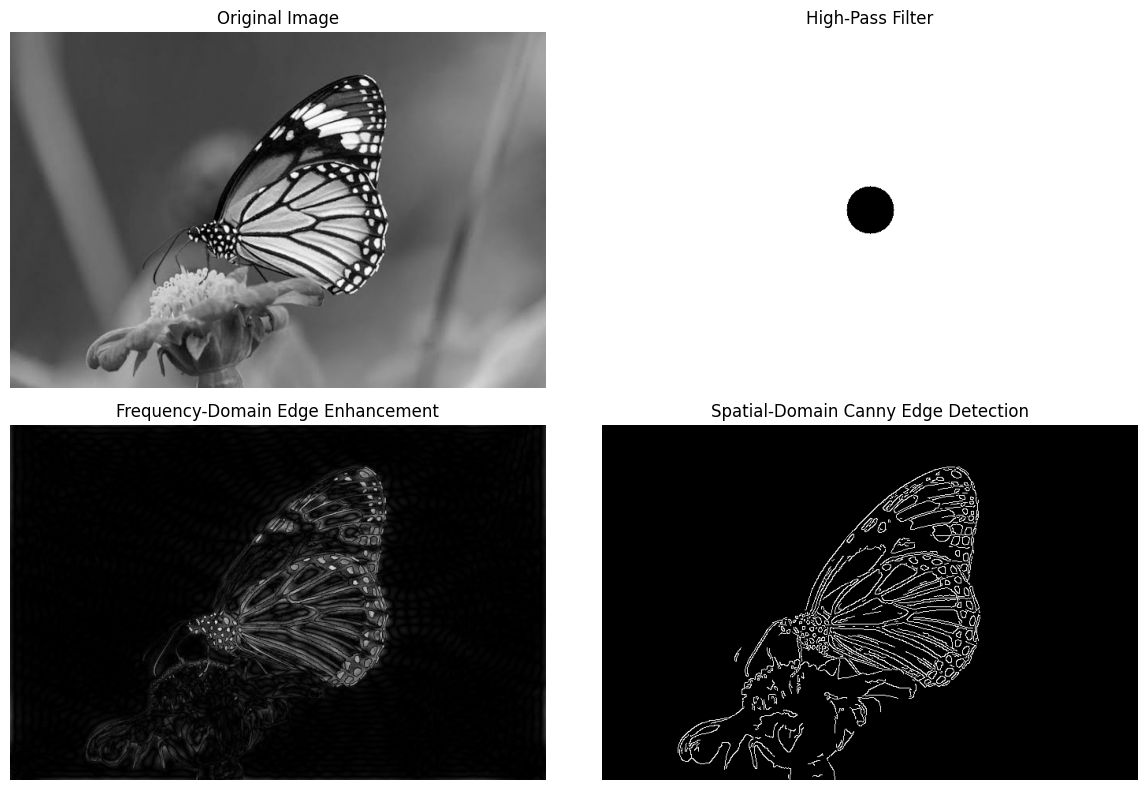

In [ ]:
# Upload image
uploaded = files.upload()
filename = next(iter(uploaded))

# Read image
img = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Error: Image could not be loaded.")
else:
    # Fourier Transform
    f = np.fft.fft2(img)
    fshift = np.fft.fftshift(f)

    rows, cols = img.shape
    crow, ccol = rows // 2, cols // 2

    # Create distance matrix
    y, x = np.ogrid[:rows, :cols]
    D = np.sqrt((x - ccol) ** 2 + (y - crow) ** 2)

    # Cutoff frequency
    D0 = 30

    # High-pass filter
    H = np.ones((rows, cols))
    H[D <= D0] = 0

    # Apply high-pass filter
    high_pass = fshift * H

    # Inverse Fourier Transform
    edge_freq = np.abs(
        np.fft.ifft2(np.fft.ifftshift(high_pass))
    )

    # Normalize for display
    edge_freq = cv2.normalize(
        edge_freq, None, 0, 255, cv2.NORM_MINMAX
    ).astype(np.uint8)

    # Spatial-domain edge detection
    edges_canny = cv2.Canny(img, 100, 200)

    # Display results
    plt.figure(figsize=(12, 8))

    plt.subplot(2, 2, 1)
    plt.imshow(img, cmap='gray')
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(2, 2, 2)
    plt.imshow(H, cmap='gray')
    plt.title("High-Pass Filter")
    plt.axis("off")

    plt.subplot(2, 2, 3)
    plt.imshow(edge_freq, cmap='gray')
    plt.title("Frequency-Domain Edge Enhancement")
    plt.axis("off")

    plt.subplot(2, 2, 4)
    plt.imshow(edges_canny, cmap='gray')
    plt.title("Spatial-Domain Canny Edge Detection")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

The frequency-domain high-pass filter suppresses low-frequency components and preserves high-frequency components, thereby enhancing edges and fine image details. Canny edge detection directly identifies strong intensity boundaries in the spatial domain and generally produces a cleaner binary edge map.

**4. Build a periodic-noise removal too that identifies and removes noise spikes visible in the frequency spectrum.**

Saving pic(dog).jpg to pic(dog) (1).jpg


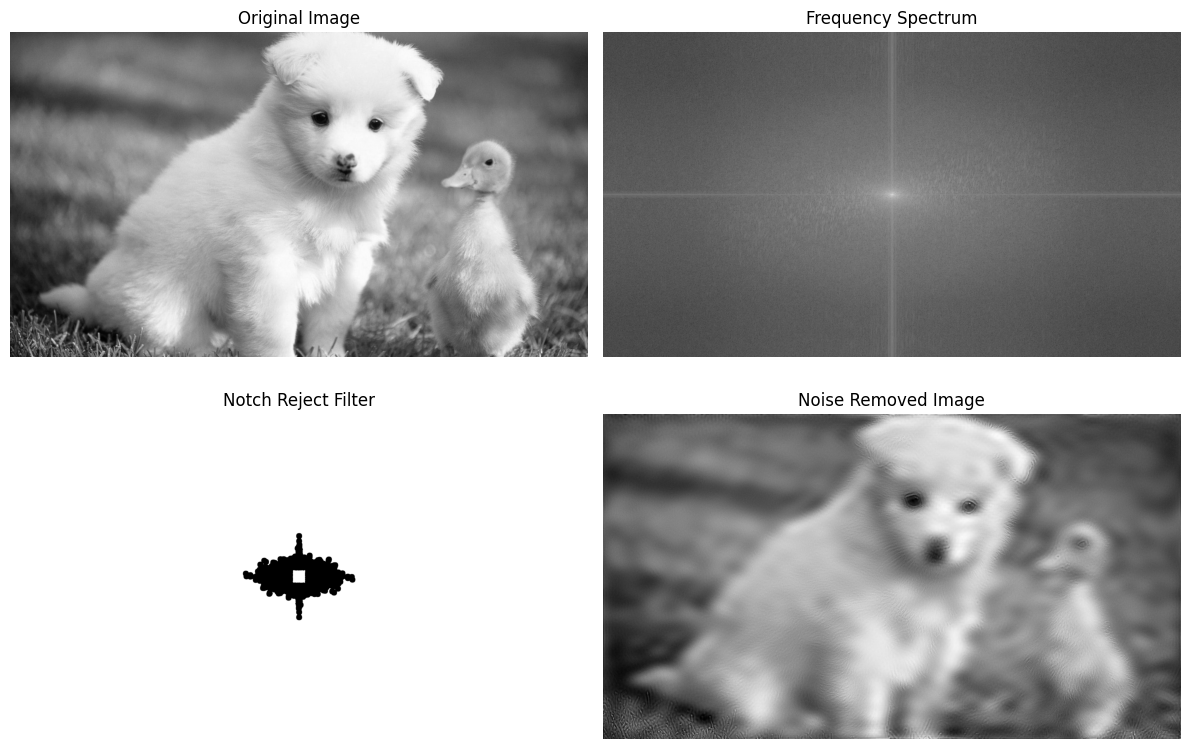

In [ ]:
# Upload image
uploaded = files.upload()
filename = next(iter(uploaded))

# Read image
img = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Error: Image could not be loaded.")
else:
    # Fourier Transform
    f = np.fft.fft2(img)
    fshift = np.fft.fftshift(f)

    # Magnitude spectrum
    magnitude = 20 * np.log(np.abs(fshift) + 1)

    rows, cols = img.shape
    crow, ccol = rows // 2, cols // 2

    # Create notch reject filter
    H = np.ones((rows, cols), np.float32)

    # Notch radius
    radius = 10

    # Automatically detect strong frequency spikes
    spectrum = magnitude.copy()

    # Ignore the central low-frequency region
    center_radius = 30
    spectrum[
        crow-center_radius:crow+center_radius,
        ccol-center_radius:ccol+center_radius
    ] = 0

    # Select strongest frequency points
    threshold = np.percentile(spectrum, 99.7)
    spike_points = np.argwhere(spectrum > threshold)

    # Remove frequency spikes
    for y, x in spike_points:
        if np.sqrt((x-ccol)**2 + (y-crow)**2) > center_radius:
            cv2.circle(H, (x, y), radius, 0, -1)

    # Apply notch filter
    filtered_spectrum = fshift * H

    # Inverse Fourier Transform
    restored = np.abs(
        np.fft.ifft2(np.fft.ifftshift(filtered_spectrum))
    )

    restored = cv2.normalize(
        restored, None, 0, 255, cv2.NORM_MINMAX
    ).astype(np.uint8)

    # Display results
    plt.figure(figsize=(12, 8))

    plt.subplot(2, 2, 1)
    plt.imshow(img, cmap='gray')
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(2, 2, 2)
    plt.imshow(magnitude, cmap='gray')
    plt.title("Frequency Spectrum")
    plt.axis("off")

    plt.subplot(2, 2, 3)
    plt.imshow(H, cmap='gray')
    plt.title("Notch Reject Filter")
    plt.axis("off")

    plt.subplot(2, 2, 4)
    plt.imshow(restored, cmap='gray')
    plt.title("Noise Removed Image")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

**5. Develop a program that compresses an imasge by retaining only the top-k Fourier coefficients and reconstructs it.**

Saving pic(butterfly).jpg to pic(butterfly) (2).jpg


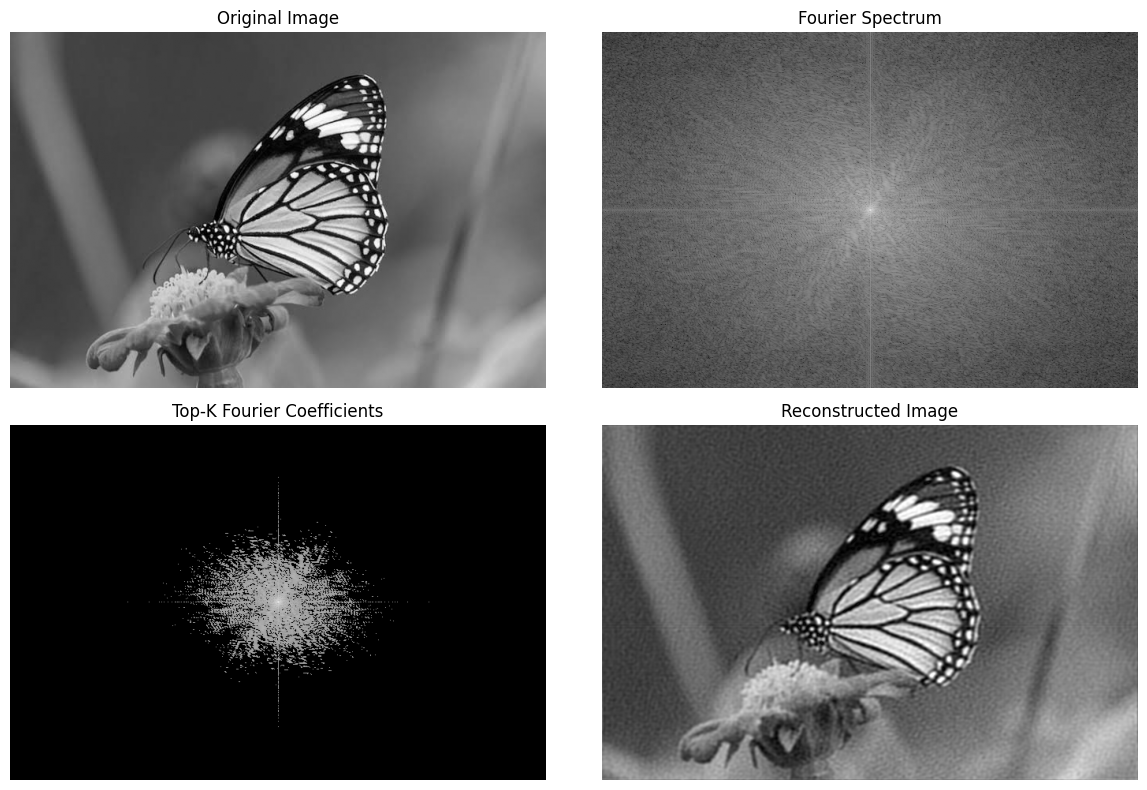

Total Fourier coefficients: 306680
Retained coefficients: 15334
Coefficients retained: 5.00%


In [ ]:
# Upload image
uploaded = files.upload()
filename = next(iter(uploaded))

# Read image
img = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Error: Image could not be loaded.")
else:
    # Fourier Transform
    f = np.fft.fft2(img)
    fshift = np.fft.fftshift(f)

    # Magnitude of Fourier coefficients
    magnitude = np.abs(fshift)

    # Number of coefficients to retain
    k = int(0.05 * img.size)

    # Find top-k coefficients
    flat_magnitude = magnitude.flatten()
    threshold = np.partition(flat_magnitude, -k)[-k]

    # Keep only top-k coefficients
    mask = magnitude >= threshold
    compressed = fshift * mask

    # Reconstruct image
    reconstructed = np.abs(
        np.fft.ifft2(np.fft.ifftshift(compressed))
    )

    reconstructed = np.clip(reconstructed, 0, 255).astype(np.uint8)

    # Calculate compression percentage
    retained = np.sum(mask)
    percentage = (retained / img.size) * 100

    # Display results
    plt.figure(figsize=(12, 8))

    plt.subplot(2, 2, 1)
    plt.imshow(img, cmap='gray')
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(2, 2, 2)
    plt.imshow(np.log1p(magnitude), cmap='gray')
    plt.title("Fourier Spectrum")
    plt.axis("off")

    plt.subplot(2, 2, 3)
    plt.imshow(np.log1p(np.abs(compressed)), cmap='gray')
    plt.title("Top-K Fourier Coefficients")
    plt.axis("off")

    plt.subplot(2, 2, 4)
    plt.imshow(reconstructed, cmap='gray')
    plt.title("Reconstructed Image")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    print("Total Fourier coefficients:", img.size)
    print("Retained coefficients:", retained)
    print("Coefficients retained: {:.2f}%".format(percentage))

**6. Create a watermark hide/reveal tool that embeds and extracts a watermark using frequency- domain manipulation.**

Upload the cover image:


Saving pic(butterfly).jpg to pic(butterfly) (3).jpg
Upload the watermark image:


Saving pic(dog).jpg to pic(dog) (2).jpg


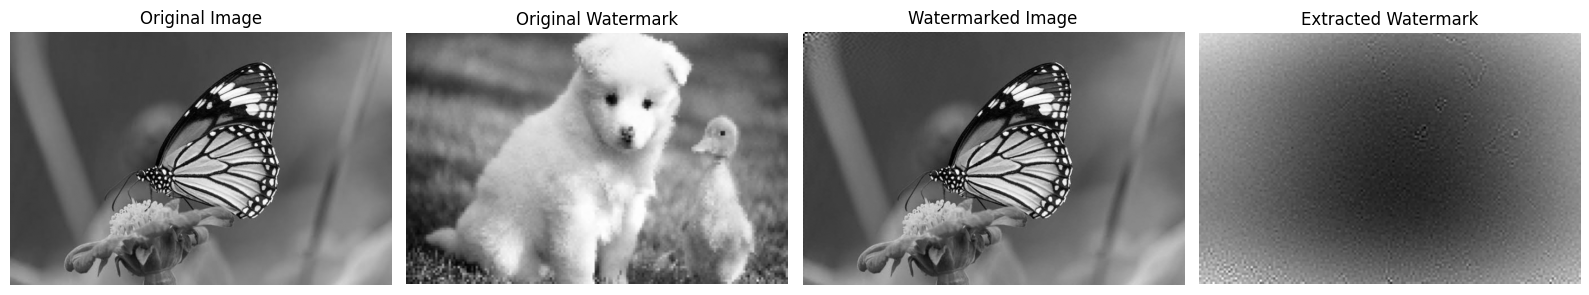

Watermark embedded successfully.
Watermark extracted successfully.


In [ ]:
# Upload cover image
print("Upload the cover image:")
uploaded = files.upload()
cover_filename = next(iter(uploaded))

# Upload watermark image
print("Upload the watermark image:")
uploaded = files.upload()
watermark_filename = next(iter(uploaded))

# Read images
cover = cv2.imread(cover_filename, cv2.IMREAD_GRAYSCALE)
watermark = cv2.imread(watermark_filename, cv2.IMREAD_GRAYSCALE)

if cover is None or watermark is None:
    print("Error: Image could not be loaded.")
else:

    # Resize watermark to a smaller size
    watermark = cv2.resize(
        watermark,
        (cover.shape[1] // 4, cover.shape[0] // 4)
    )

    # Normalize watermark
    watermark = watermark.astype(np.float32) / 255.0

    # Convert cover image to float
    cover_float = cover.astype(np.float32)

    # Apply DCT
    dct = cv2.dct(cover_float)

    # Watermark position
    h, w = watermark.shape

    # Embedding strength
    alpha = 30

    # Embed watermark into middle-frequency coefficients
    dct[20:20+h, 20:20+w] += alpha * watermark

    # Apply inverse DCT
    watermarked = cv2.idct(dct)

    # Keep pixel values valid
    watermarked = np.clip(
        watermarked,
        0,
        255
    ).astype(np.uint8)

    # Save watermarked image
    cv2.imwrite(
        "watermarked_frequency.png",
        watermarked
    )

    # Convert watermarked image to float
    watermarked_float = watermarked.astype(np.float32)

    # Apply DCT again
    dct_watermarked = cv2.dct(
        watermarked_float
    )

    # Extract watermark coefficients
    extracted = (
        dct_watermarked[20:20+h, 20:20+w]
        - dct[20:20+h, 20:20+w]
    ) / alpha

    # Normalize extracted watermark
    extracted = cv2.normalize(
        extracted,
        None,
        0,
        255,
        cv2.NORM_MINMAX
    ).astype(np.uint8)

    # Save extracted watermark
    cv2.imwrite(
        "extracted_watermark.png",
        extracted
    )

    plt.figure(figsize=(16, 5))

    plt.subplot(1, 4, 1)
    plt.imshow(cover, cmap="gray")
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 4, 2)
    plt.imshow(watermark, cmap="gray")
    plt.title("Original Watermark")
    plt.axis("off")

    plt.subplot(1, 4, 3)
    plt.imshow(watermarked, cmap="gray")
    plt.title("Watermarked Image")
    plt.axis("off")

    plt.subplot(1, 4, 4)
    plt.imshow(extracted, cmap="gray")
    plt.title("Extracted Watermark")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    print("Watermark embedded successfully.")
    print("Watermark extracted successfully.")

**7. Build a band-pass / band-reject filter designer for isolating specific frequency ranges in a textured image.**

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output
from google.colab import files

# Upload textured image
uploaded = files.upload()
filename = next(iter(uploaded))

# Read image
image = cv2.imread(
    filename,
    cv2.IMREAD_GRAYSCALE
)

if image is None:
    print("Error: Image could not be loaded.")

else:

    def frequency_filter(
        image,
        low_cut,
        high_cut,
        filter_type
    ):

        # Fourier Transform
        f = np.fft.fft2(image)
        fshift = np.fft.fftshift(f)

        # Frequency coordinates
        rows, cols = image.shape
        crow, ccol = rows // 2, cols // 2

        y, x = np.ogrid[:rows, :cols]

        distance = np.sqrt(
            (x - ccol) ** 2 +
            (y - crow) ** 2
        )

        # Create filter
        if filter_type == "Band-Pass":

            mask = (
                (distance >= low_cut) &
                (distance <= high_cut)
            ).astype(np.float32)

        else:

            mask = (
                (distance < low_cut) |
                (distance > high_cut)
            ).astype(np.float32)

        # Apply filter
        filtered_frequency = fshift * mask

        # Inverse Fourier Transform
        ishift = np.fft.ifftshift(
            filtered_frequency
        )

        result = np.fft.ifft2(ishift)

        result = np.abs(result)

        result = cv2.normalize(
            result,
            None,
            0,
            255,
            cv2.NORM_MINMAX
        ).astype(np.uint8)

        return mask, result


    # Low cutoff slider
    low_slider = widgets.IntSlider(
        value=20,
        min=1,
        max=150,
        step=1,
        description="Low Cut:"
    )

    # High cutoff slider
    high_slider = widgets.IntSlider(
        value=80,
        min=10,
        max=200,
        step=1,
        description="High Cut:"
    )

    # Filter selection
    filter_dropdown = widgets.Dropdown(
        options=[
            "Band-Pass",
            "Band-Reject"
        ],
        value="Band-Pass",
        description="Filter:"
    )

    output = widgets.Output()


    def update(change=None):

        with output:

            clear_output(wait=True)

            low_cut = low_slider.value
            high_cut = high_slider.value

            if high_cut <= low_cut:

                print(
                    "High Cut must be greater than Low Cut."
                )

                return

            mask, result = frequency_filter(
                image,
                low_cut,
                high_cut,
                filter_dropdown.value
            )

            # Frequency spectrum
            spectrum = np.log1p(
                np.abs(
                    np.fft.fftshift(
                        np.fft.fft2(image)
                    )
                )
            )

            # Display
            plt.figure(figsize=(16, 5))

            plt.subplot(1, 4, 1)
            plt.imshow(
                image,
                cmap="gray"
            )
            plt.title("Original Texture")
            plt.axis("off")

            plt.subplot(1, 4, 2)
            plt.imshow(
                spectrum,
                cmap="gray"
            )
            plt.title("Frequency Spectrum")
            plt.axis("off")

            plt.subplot(1, 4, 3)
            plt.imshow(
                mask,
                cmap="gray"
            )
            plt.title(
                filter_dropdown.value
            )
            plt.axis("off")

            plt.subplot(1, 4, 4)
            plt.imshow(
                result,
                cmap="gray"
            )
            plt.title("Filtered Texture")
            plt.axis("off")

            plt.tight_layout()
            plt.show()


    # Connect sliders
    low_slider.observe(
        update,
        names="value"
    )

    high_slider.observe(
        update,
        names="value"
    )

    filter_dropdown.observe(
        update,
        names="value"
    )

    # Initial output
    update()

    # Display controls
    display(
        low_slider,
        high_slider,
        filter_dropdown,
        output
    )

Saving pic(dog).jpg to pic(dog) (6).jpg


IntSlider(value=20, description='Low Cut:', max=150, min=1)

IntSlider(value=80, description='High Cut:', max=200, min=10)

Dropdown(description='Filter:', options=('Band-Pass', 'Band-Reject'), value='Band-Pass')

Output()

**8. Develop a demo that swaps the phase and magnitude components between two images to show their relative importance.**

Upload Image 1:


Saving pic(butterfly).jpg to pic(butterfly) (5).jpg
Upload Image 2:


Saving pic(dog).jpg to pic(dog) (3).jpg


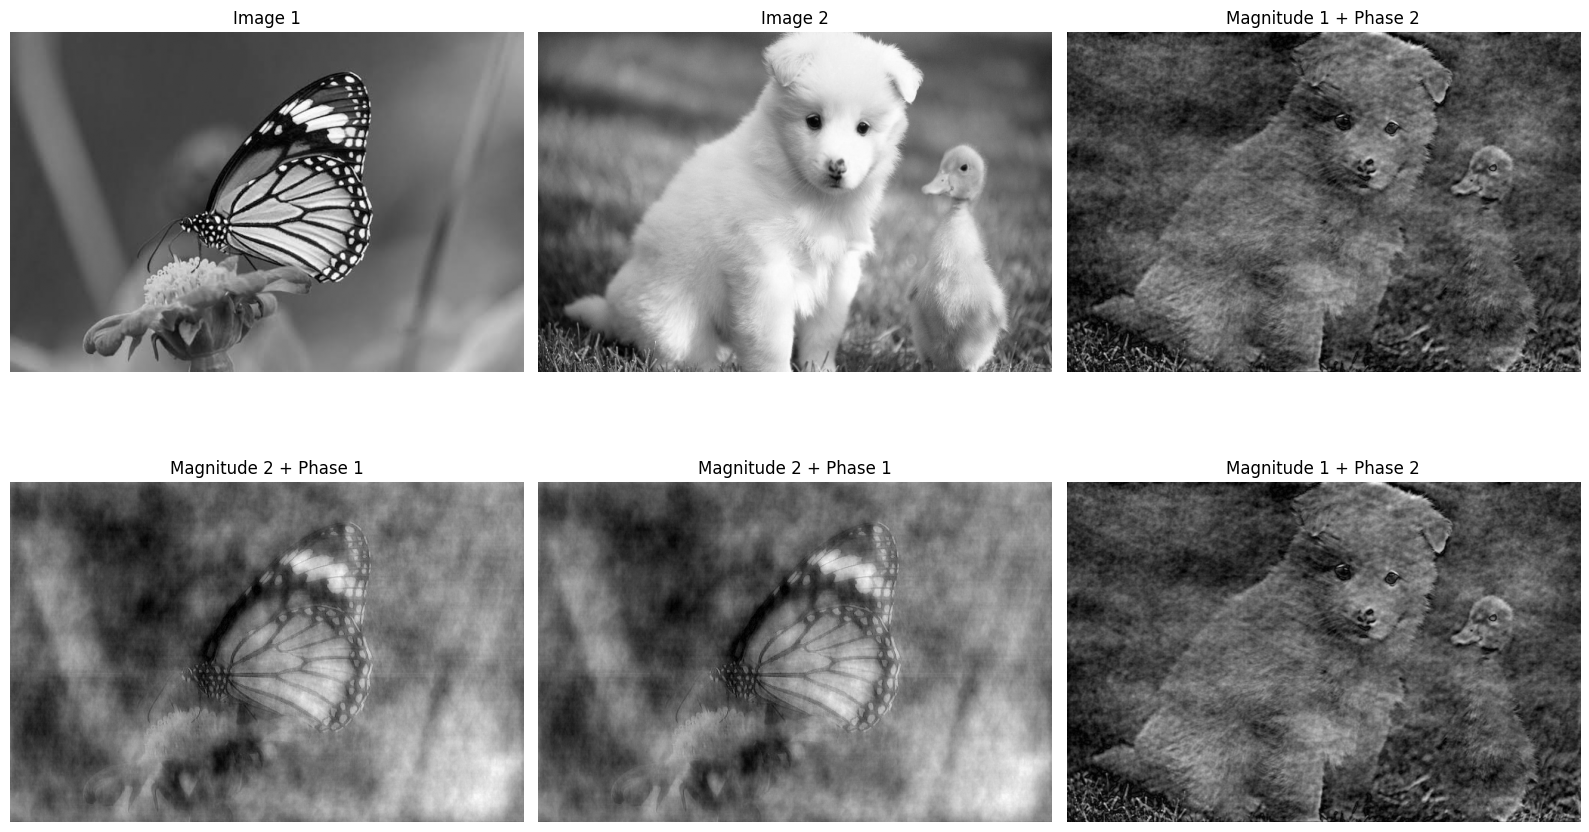

In [ ]:
# Upload first image
print("Upload Image 1:")
uploaded1 = files.upload()
file1 = next(iter(uploaded1))

# Upload second image
print("Upload Image 2:")
uploaded2 = files.upload()
file2 = next(iter(uploaded2))

# Read images
img1 = cv2.imread(file1, cv2.IMREAD_GRAYSCALE)
img2 = cv2.imread(file2, cv2.IMREAD_GRAYSCALE)

if img1 is None or img2 is None:
    print("Error: Images could not be loaded.")
else:

    # Resize second image to match first image
    img2 = cv2.resize(
        img2,
        (img1.shape[1], img1.shape[0])
    )

    # Fourier Transform
    fft1 = np.fft.fft2(img1)
    fft2 = np.fft.fft2(img2)

    # Magnitude and phase
    magnitude1 = np.abs(fft1)
    phase1 = np.angle(fft1)

    magnitude2 = np.abs(fft2)
    phase2 = np.angle(fft2)

    phase_swap_1 = magnitude1 * np.exp(1j * phase2)
    phase_swap_2 = magnitude2 * np.exp(1j * phase1)

    result_phase_1 = np.abs(
        np.fft.ifft2(phase_swap_1)
    )

    result_phase_2 = np.abs(
        np.fft.ifft2(phase_swap_2)
    )

    magnitude_swap_1 = magnitude2 * np.exp(1j * phase1)
    magnitude_swap_2 = magnitude1 * np.exp(1j * phase2)

    result_magnitude_1 = np.abs(
        np.fft.ifft2(magnitude_swap_1)
    )

    result_magnitude_2 = np.abs(
        np.fft.ifft2(magnitude_swap_2)
    )

    # Normalize results
    def normalize_image(image):
        return cv2.normalize(
            image,
            None,
            0,
            255,
            cv2.NORM_MINMAX
        ).astype(np.uint8)

    result_phase_1 = normalize_image(result_phase_1)
    result_phase_2 = normalize_image(result_phase_2)

    result_magnitude_1 = normalize_image(
        result_magnitude_1
    )

    result_magnitude_2 = normalize_image(
        result_magnitude_2
    )

    plt.figure(figsize=(16, 10))

    plt.subplot(2, 3, 1)
    plt.imshow(img1, cmap="gray")
    plt.title("Image 1")
    plt.axis("off")

    plt.subplot(2, 3, 2)
    plt.imshow(img2, cmap="gray")
    plt.title("Image 2")
    plt.axis("off")

    plt.subplot(2, 3, 3)
    plt.imshow(result_phase_1, cmap="gray")
    plt.title("Magnitude 1 + Phase 2")
    plt.axis("off")

    plt.subplot(2, 3, 4)
    plt.imshow(result_phase_2, cmap="gray")
    plt.title("Magnitude 2 + Phase 1")
    plt.axis("off")

    plt.subplot(2, 3, 5)
    plt.imshow(result_magnitude_1, cmap="gray")
    plt.title("Magnitude 2 + Phase 1")
    plt.axis("off")

    plt.subplot(2, 3, 6)
    plt.imshow(result_magnitude_2, cmap="gray")
    plt.title("Magnitude 1 + Phase 2")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

**9. Create a blur-defection tool that flags blurry images based on the high-frequency energy content of their spectrum.**

Saving pic(dog).jpg to pic(dog) (4).jpg


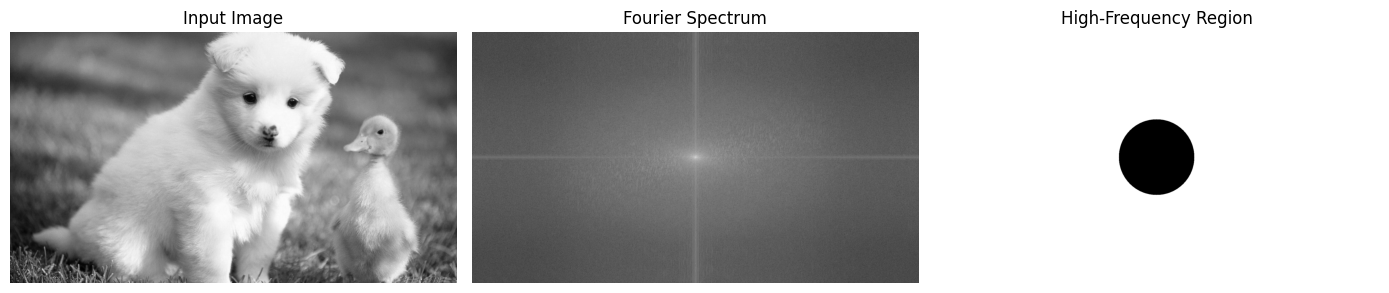

High-Frequency Energy: 80382918649400.47
Total Frequency Energy: 1.0073134013022728e+17
High-Frequency Energy Ratio: 0.0007979931424071197
Result: BLURRED


In [ ]:
# Upload image
uploaded = files.upload()
filename = next(iter(uploaded))

# Read image
image = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)

if image is None:
    print("Error: Image could not be loaded.")
else:

    # Fourier Transform
    fft = np.fft.fft2(image)
    fft_shift = np.fft.fftshift(fft)

    # Magnitude spectrum
    magnitude = np.abs(fft_shift)

    # Frequency coordinates
    rows, cols = image.shape
    crow, ccol = rows // 2, cols // 2

    y, x = np.ogrid[:rows, :cols]

    distance = np.sqrt(
        (x - ccol) ** 2 +
        (y - crow) ** 2
    )

    # Define high-frequency region
    radius = min(rows, cols) * 0.15

    high_frequency_mask = distance > radius

    # Calculate high-frequency energy
    high_frequency_energy = np.sum(
        magnitude[high_frequency_mask] ** 2
    )

    # Total frequency energy
    total_energy = np.sum(
        magnitude ** 2
    )

    # High-frequency energy ratio
    energy_ratio = (
        high_frequency_energy /
        total_energy
    )

    # Threshold for blur detection
    threshold = 0.10

    if energy_ratio < threshold:
        result = "BLURRED"
    else:
        result = "SHARP"

    # Display spectrum
    spectrum = np.log1p(magnitude)

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(image, cmap="gray")
    plt.title("Input Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(
        spectrum,
        cmap="gray"
    )
    plt.title("Fourier Spectrum")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(
        high_frequency_mask,
        cmap="gray"
    )
    plt.title("High-Frequency Region")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    print("High-Frequency Energy:", high_frequency_energy)
    print("Total Frequency Energy:", total_energy)
    print("High-Frequency Energy Ratio:", energy_ratio)
    print("Result:", result)

**Mishti Verma, CU24250174**

**10. Build a side-by-side visualizer comparing spatial-domain and frequency-domain filtering results for the same image.**

Saving pic(dog).jpg to pic(dog) (5).jpg


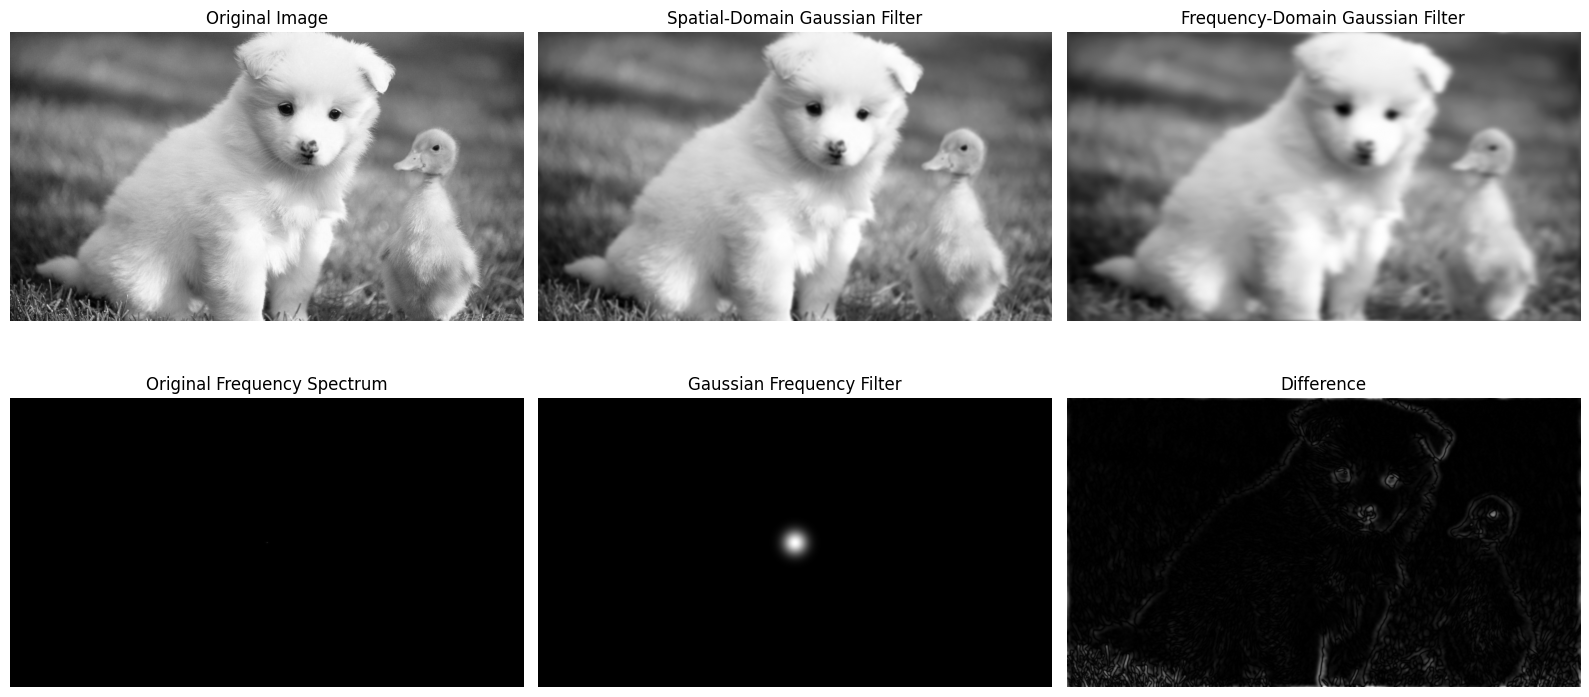

Mean Difference Between Results: 2.971122202932099


In [ ]:
# Upload image
uploaded = files.upload()
filename = next(iter(uploaded))

# Read image
image = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)

if image is None:
    print("Error: Image could not be loaded.")
else:
    spatial_result = cv2.GaussianBlur(
        image,
        (15, 15),
        3
    )

    # Fourier Transform
    fft = np.fft.fft2(image)
    fft_shift = np.fft.fftshift(fft)

    rows, cols = image.shape
    crow, ccol = rows // 2, cols // 2

    y, x = np.ogrid[:rows, :cols]

    distance_squared = (
        (x - ccol) ** 2 +
        (y - crow) ** 2
    )

    # Gaussian low-pass filter
    sigma = 30

    gaussian_filter = np.exp(
        -distance_squared /
        (2 * sigma ** 2)
    )

    # Apply filter
    filtered_fft = fft_shift * gaussian_filter

    # Inverse Fourier Transform
    inverse_shift = np.fft.ifftshift(
        filtered_fft
    )

    frequency_result = np.abs(
        np.fft.ifft2(inverse_shift)
    )

    frequency_result = np.clip(
        frequency_result,
        0,
        255
    ).astype(np.uint8)

    plt.figure(figsize=(16, 8))

    plt.subplot(2, 3, 1)
    plt.imshow(image, cmap="gray")
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(2, 3, 2)
    plt.imshow(spatial_result, cmap="gray")
    plt.title("Spatial-Domain Gaussian Filter")
    plt.axis("off")

    plt.subplot(2, 3, 3)
    plt.imshow(frequency_result, cmap="gray")
    plt.title("Frequency-Domain Gaussian Filter")
    plt.axis("off")

    plt.subplot(2, 3, 4)
    plt.imshow(
        np.abs(
            np.fft.fftshift(
                np.fft.fft2(image)
            )
        ),
        cmap="gray"
    )
    plt.title("Original Frequency Spectrum")
    plt.axis("off")

    plt.subplot(2, 3, 5)
    plt.imshow(
        gaussian_filter,
        cmap="gray"
    )
    plt.title("Gaussian Frequency Filter")
    plt.axis("off")

    plt.subplot(2, 3, 6)
    difference = cv2.absdiff(
        spatial_result,
        frequency_result
    )
    plt.imshow(
        difference,
        cmap="gray"
    )
    plt.title("Difference")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    # Mean difference
    mean_difference = np.mean(difference)

    print(
        "Mean Difference Between Results:",
        mean_difference
    )